# NYC Department of Buildings permit applications for apartment alterations
**Group Members** Ugochinyere Megwa, Sneha Sachin Shenoy, Álvaro Miñé

**DAY 1 Cleaning and EDA**

### Goal

What drives the cost of apartment renovations in New York City, and how has it changed over time and across boroughs?

## Overview

This analysis explores 13,500 apartment renovation permits filed with the NYC Department of Buildings to understand how renovation costs vary by borough, job type, zoning and time, and which factors are most associated with higher-cost projects. 



# Setup and Data

## 0.1 Libararies

Import necessary modules 

In [1]:
# %pip install -r ../requirements.txt

In [2]:
#import all required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from matplotlib.ticker import FuncFormatter, MaxNLocator
import matplotlib.dates as mdates

# Project folders (paths are relative to notebook/)
DATA_DIR = Path("../data")
FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(exist_ok=True)

def save_fig(name):
    """Save the current figure to figures/ so it can be regenerated from the notebook."""
    plt.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


### 0.2 Collecting the Data

We collected the Data from Kaggle. The NYC Housing dataset contains information about the New York City Housing and Preservation Department's (HPD) affordable housing development projects. It includes data on building characteristics, affordability levels, location, and ownership information for all properties in the dataset.

In [3]:
#reading the csv file
df = pd.read_csv(DATA_DIR / "apartment_data.csv")

### 0.3 First Look


In [4]:
df.head()

,Job #,Borough,House #,Street Name,Block,Lot,Bin #,Job Type,Community - Board,Curb Cut,Fully Permitted,Initial Cost,Proposed Zoning Sqft,Horizontal Enlrgmt,Vertical Enlrgmt,Enlargement SQ Footage,Zoning Dist1,Job Description
0,123768976,MANHATTAN,1598,2ND AVENUE,1545,49,1049907,A2,108,NaN,NaN,"$65,000.00",0,NaN,NaN,0,C1-9,INTERIOR RENOVATION TO COMBINE APARTMENT 2E AN...
1,140922893,MANHATTAN,160,E 89 ST,1517,43,1048094,A2,108,NaN,07/14/2020,"$85,000.00",0,NaN,NaN,0,R8B,HEREBY FILING APPLICATION FOR THE INTERIOR REN...
2,301773579,BROOKLYN,65,GATES AVENUE,1962,86,3056039,A1,302,NaN,05/23/2007,"$60,000.00",0,NaN,NaN,0,R6,Change existing four story and basement brick ...
3,301976057,BROOKLYN,1401,OCEAN AVENUE,7584,35,3206621,A2,314,NaN,02/28/2006,"$75,000.00",0,NaN,NaN,0,NaN,COMBINING OF APARTMENT 4A &amp; 4L.NO CHANGEIN...
4,301989276,BROOKLYN,154,NOBLE STREET,2573,10,3065099,A1,301,NaN,09/29/2006,"$40,000.00",0,NaN,NaN,0,C4-3,New C of O for existing building. New duplex a...


In [5]:
# information in columns
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Job #,19613.0,NaN,NaN,NaN,162426590.843063,91577222.331873,102133077.0,104824424.0,121711228.0,140825846.0,540180276.0
Borough,19613,5,MANHATTAN,15341,NaN,NaN,NaN,NaN,NaN,NaN,NaN
House #,19613,1959,200,237,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Street Name,19613,2580,PARK AVENUE,675,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Block,19613.0,NaN,NaN,NaN,1551.725794,1550.780753,0.0,816.0,1245.0,1576.0,16278.0
Lot,19613.0,NaN,NaN,NaN,1261.811197,2764.626109,0.0,17.0,36.0,66.0,9007.0
Bin #,19613.0,NaN,NaN,NaN,1506364.505328,931999.249497,1000043.0,1028758.0,1046983.0,1084564.0,5860016.0
Job Type,19613,3,A2,18126,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Community - Board,19613.0,NaN,NaN,NaN,151.269005,90.115653,101.0,105.0,107.0,111.0,503.0
Curb Cut,16,1,X,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN


This table summarises every column in the raw dataset (19,613 rows). Each row is a column from the data, and the table shows two kinds of information:

- **Text columns** (e.g. Borough, Job Type) use `unique` (number of different values), `top` (most common value) and `freq` (how many times the top value appears).
- **Numeric columns** (e.g. Block, Lot) use `mean`, `std` (spread), `min`, `max` and the quartiles (`25%`, `50%` = median, `75%`).
- `count` shows how many rows have a value. If it is below 19,613, that column has missing data.
- `NaN` means that statistic does not apply to that type of column.

**What this tells us about the data:**

- **Initial Cost is stored as text** (e.g. `$40,000.00`), so it shows no mean or median. It must be converted to a number before analysis. It also has only **46 unique values**, meaning applicants enter rounded estimates.
- **The data is unbalanced:** Manhattan accounts for 15,341 permits (about 78%), and job type A2 accounts for 18,126 (about 92%).
- **Several columns are almost empty:** Curb Cut (16 values), Horizontal Enlargement (163) and Vertical Enlargement (242). Proposed Zoning Sqft and Enlargement SQ Footage are mostly 0. These columns are removed during cleaning.
- **Some values are missing:** about 4,000 permits have no Fully Permitted date, and about 2,100 have no zoning district.
- **Job #, Block, Lot, Bin # and Community Board are ID codes,** not measurements, so their mean and standard deviation have no real meaning.
- **Job Description has only 12,871 unique values out of 19,613 rows,** an early sign of the duplicate rows removed later in cleaning.

In [6]:
# finding columns to remove
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19613 entries, 0 to 19612
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Job #                   19613 non-null  int64 
 1   Borough                 19613 non-null  object
 2   House #                 19613 non-null  object
 3   Street Name             19613 non-null  object
 4   Block                   19613 non-null  int64 
 5   Lot                     19613 non-null  int64 
 6   Bin #                   19613 non-null  int64 
 7   Job Type                19613 non-null  object
 8   Community - Board       19613 non-null  int64 
 9   Curb Cut                16 non-null     object
 10  Fully Permitted         15625 non-null  object
 11  Initial Cost            19613 non-null  object
 12  Proposed Zoning Sqft    19613 non-null  int64 
 13  Horizontal Enlrgmt      163 non-null    object
 14  Vertical Enlrgmt        242 non-null    object
 15  En

## 1. Data Cleaning

In [7]:
#create a copy to edit and work with
df_clean = df.copy()

### 1.1 Empty Columns 

From the analysis we can tell a few columns are very empty and we need to remove them.

In [8]:
#removing columns with over 95% missing values
df_clean = df_clean.drop(['Curb Cut', 'Proposed Zoning Sqft', 'Horizontal Enlrgmt', 'Vertical Enlrgmt', 'Enlargement SQ Footage' ], axis=1)


### 1.2 Missing Values

Checking what data has more than 2 missing values

In [9]:
df_clean.isnull().sum(axis=1)

0        1
1        0
2        0
3        1
4        0
        ..
19608    0
19609    0
19610    0
19611    1
19612    1
Length: 19613, dtype: int64

In [10]:
#checking for rows with more than 2 missing values
df_clean[df_clean.isnull().sum(axis=1) > 0]

,Job #,Borough,House #,Street Name,Block,Lot,Bin #,Job Type,Community - Board,Fully Permitted,Initial Cost,Zoning Dist1,Job Description
0,123768976,MANHATTAN,1598,2ND AVENUE,1545,49,1049907,A2,108,NaN,"$65,000.00",C1-9,INTERIOR RENOVATION TO COMBINE APARTMENT 2E AN...
3,301976057,BROOKLYN,1401,OCEAN AVENUE,7584,35,3206621,A2,314,02/28/2006,"$75,000.00",NaN,COMBINING OF APARTMENT 4A &amp; 4L.NO CHANGEIN...
11,302022656,BROOKLYN,6,2 STREET,460,2,3007811,A2,306,04/23/2008,"$60,000.00",NaN,RENOVATE EXISTING LOWER DUPLEX APARTMENT. NO C...
12,102614048,MANHATTAN,730,PARK AVENUE,1385,37,1041333,A2,108,05/10/2000,"$75,000.00",NaN,Minor renovation to existing apartment to incl...
13,302026849,BROOKLYN,1054,WILLOUGHBY AVENUE,3208,11,3325441,A2,304,NaN,"$40,000.00",R6,Application being filed to renovate existing s...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
19579,104477870,MANHATTAN,160,CENTRAL PARK SOUTH,1011,7501,1023760,A2,105,09/15/2006,"$85,000.00",NaN,RENOVATION OF AN EXISTING APARTMENTON THE 9TH ...
19583,321998326,BROOKLYN,126,DEAN STREET,194,32,3001265,A1,302,NaN,"$40,000.00",R6,REMOVAL AND INSTALLATION OF INTERIOR PARTITION...
19584,302221138,BROOKLYN,234,WASHINGTON AVENUE,1917,32,3055065,A1,302,NaN,"$75,000.00",R6,Proposed to convert one class 'A' apartment an...
19611,200838558,BRONX,2762,KINGSBRIDGE TERRACE,3253,90,2015521,A2,208,NaN,"$40,000.00",R6,Proposed to renovate existing apartments. No c...


### 1.3 Duplicates 

Identifying and removing duplicates

In [11]:
#checking and removing duplicates
n_duplicates = df_clean.duplicated().sum()
print(n_duplicates)
df_clean = df_clean.drop_duplicates()

6104


In [12]:
# resetting the index
df_clean = df_clean.reset_index(drop=True)

### 1.4 Reformatting

Updating Job description and Initial cost to all follow the same format

In [13]:
#formatting the Job_Description to all be capital
df_clean = df_clean.map(lambda x: x.upper() if isinstance(x, str) else x)

In [14]:
#formatting cost to remove '$' and ','
df_clean['Initial Cost'] = pd.to_numeric(
    df_clean['Initial Cost']
    .astype('string')
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False),
    errors='coerce'
)

df_clean['Initial Cost Original'] = df_clean['Initial Cost'].copy()

df_clean

,Job #,Borough,House #,Street Name,Block,Lot,Bin #,Job Type,Community - Board,Fully Permitted,Initial Cost,Zoning Dist1,Job Description,Initial Cost Original
0,123768976,MANHATTAN,1598,2ND AVENUE,1545,49,1049907,A2,108,NaN,65000.0,C1-9,INTERIOR RENOVATION TO COMBINE APARTMENT 2E AN...,65000.0
1,140922893,MANHATTAN,160,E 89 ST,1517,43,1048094,A2,108,07/14/2020,85000.0,R8B,HEREBY FILING APPLICATION FOR THE INTERIOR REN...,85000.0
2,301773579,BROOKLYN,65,GATES AVENUE,1962,86,3056039,A1,302,05/23/2007,60000.0,R6,CHANGE EXISTING FOUR STORY AND BASEMENT BRICK ...,60000.0
3,301976057,BROOKLYN,1401,OCEAN AVENUE,7584,35,3206621,A2,314,02/28/2006,75000.0,NaN,COMBINING OF APARTMENT 4A &AMP; 4L.NO CHANGEIN...,75000.0
4,301989276,BROOKLYN,154,NOBLE STREET,2573,10,3065099,A1,301,09/29/2006,40000.0,C4-3,NEW C OF O FOR EXISTING BUILDING. NEW DUPLEX A...,40000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13504,123847409,MANHATTAN,225,CENTRAL PARK WEST,1196,29,1031181,A2,107,06/11/2020,60000.0,R10A,COMBINATION OF APARTMENTS 1608 AND 1610 ON 015...,60000.0
13505,141021631,MANHATTAN,51,5TH AVENUE,569,5,1009275,A2,102,12/09/2022,40000.0,R10,LEVEL 2 RENOVATIONS: PARTIAL REMOVAL OF NON-ST...,40000.0
13506,121090112,MANHATTAN,110,DUANE STREET,150,22,1001645,A2,101,07/17/2012,40000.0,C6-2A,APARTMENT RENVOATION AT APT #4R. DEMOLISH AND ...,40000.0
13507,102937342,MANHATTAN,166,BANK STREET,638,4,1078335,A2,102,02/07/2001,80000.0,C6-2,INTERIOR RENOVATION OF AN EXISTING APARTMENT. ...,80000.0


### 1.5 Outliers

Finding outliers in initial cost

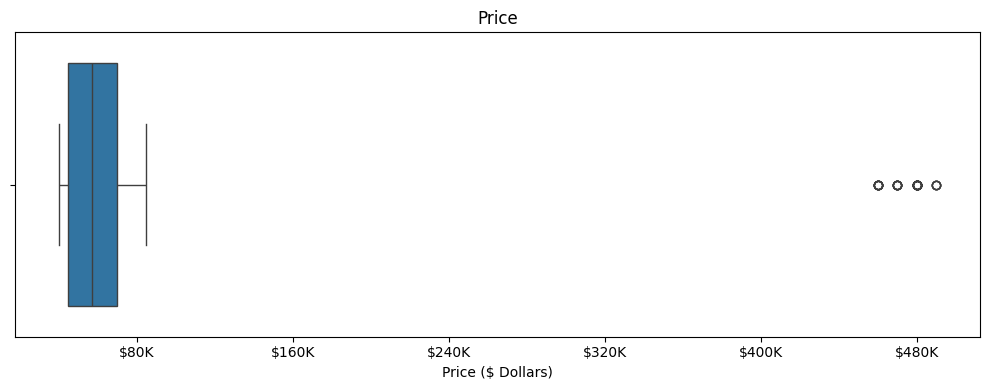

In [15]:
# intial boxplot to identify existing outliers 
df_clean["Initial Cost"] = pd.to_numeric(
    df_clean["Initial Cost"].astype(str).str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)

fig, ax = plt.subplots(figsize=(10, 4))

sns.boxplot(x=df_clean["Initial Cost"], ax=ax)

ax.set_title("Price")
ax.set_xlabel("Price ($ Dollars)")

# Format tick labels as $65K
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"${x/1000:.0f}K"))

# Limit to roughly 8 ticks
ax.xaxis.set_major_locator(MaxNLocator(nbins=8))

plt.tight_layout()
save_fig("boxplot_cost_before_outliers")
plt.show()

##### Initial Construction Cost Distribution — Before Removing Outliers

**Type:** Univariate Analysis — Initial Cost

The initial boxplot reveals several extreme outliers, with some construction costs reaching approximately $450,000–$500,000. Most observations are concentrated at much lower values, indicating a strongly right-skewed distribution. These extreme values can significantly influence statistical measures such as the mean, supporting the decision to examine a filtered dataset for comparative analysis.

In [16]:
# following IQR rule finding the outliers
price = df_clean["Initial Cost"]

# IQR rule
q1, q3 = price.quantile([0.25, 0.75])
iqr = q3 - q1
iqr_outliers = (price < q1 - 1.5 * iqr) | (price > q3 + 1.5 * iqr)
df_clean = df_clean[~iqr_outliers].reset_index(drop=True)
print(f"IQR rule:        keep {q1 - 1.5 * iqr:,.1f} to {q3 + 1.5 * iqr:,.1f} Dollars -> removes {iqr_outliers.sum():,} listings")


IQR rule:        keep 7,500.0 to 107,500.0 Dollars -> removes 39 listings


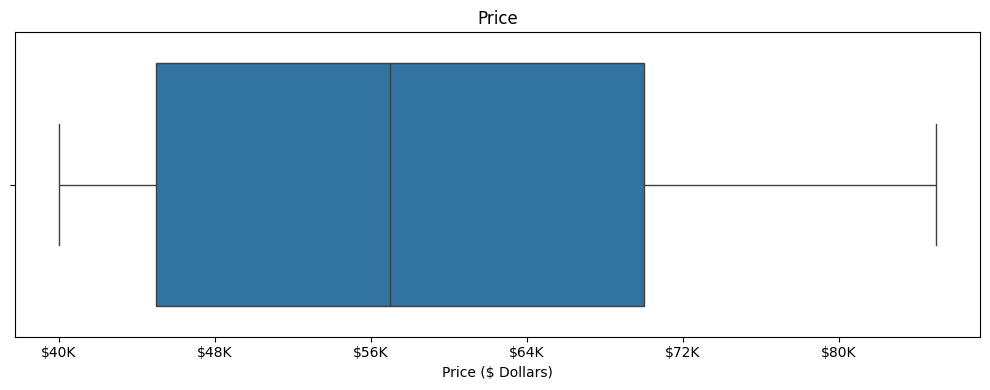

In [17]:
# removing outliers
df_clean["Initial Cost"] = pd.to_numeric(
    df_clean["Initial Cost"].astype(str).str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)

fig, ax = plt.subplots(figsize=(10, 4))

sns.boxplot(x=df_clean["Initial Cost"], ax=ax)

ax.set_title("Price")
ax.set_xlabel("Price ($ Dollars)")

# Format tick labels as $65K
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"${x/1000:.0f}K"))

# Limit to roughly 8 ticks
ax.xaxis.set_major_locator(MaxNLocator(nbins=8))

plt.tight_layout()
save_fig("boxplot_cost_after_outliers")
plt.show()

##### Construction Cost Distribution — After Removing Outliers

**Type:** Univariate Analysis — Initial Cost

The boxplot shows the distribution of construction costs after removing extreme values. Most projects fall between approximately $40,000 and $85,000, with a median close to $56,000. The distribution is relatively balanced within this selected range, making it easier to compare typical renovation costs without the influence of extreme values.

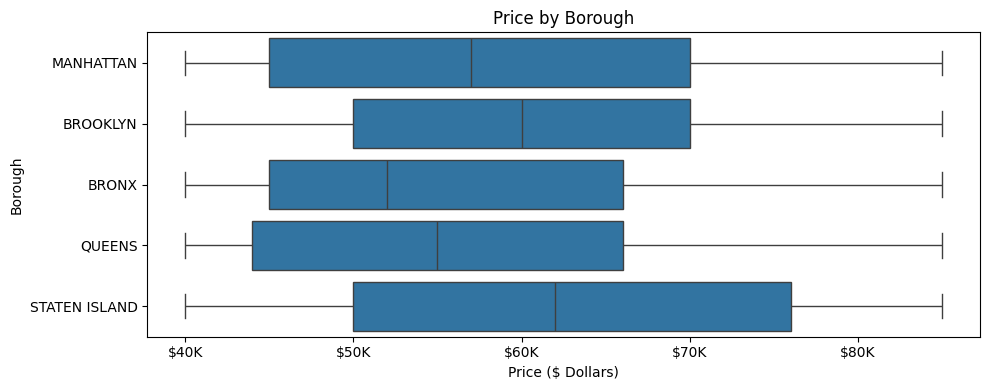

In [18]:
# finding average median cost for each borough
fig, ax = plt.subplots(figsize=(10, 4))

sns.boxplot(data=df_clean, x="Initial Cost", y="Borough", ax=ax)

ax.set_title("Price by Borough")
ax.set_xlabel("Price ($ Dollars)")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"${x/1000:.0f}K"))

plt.tight_layout()
save_fig("boxplot_cost_by_borough_cleaning")
plt.show()

##### Construction Cost by Borough

**Type:** Bivariate Analysis — Borough × Initial Cost

Brooklyn and Staten Island show the highest median construction costs, while the Bronx has the lowest. However, the distributions overlap considerably across boroughs, suggesting that geographical location alone does not strongly explain construction costs. Differences in project characteristics may also contribute to cost variation.

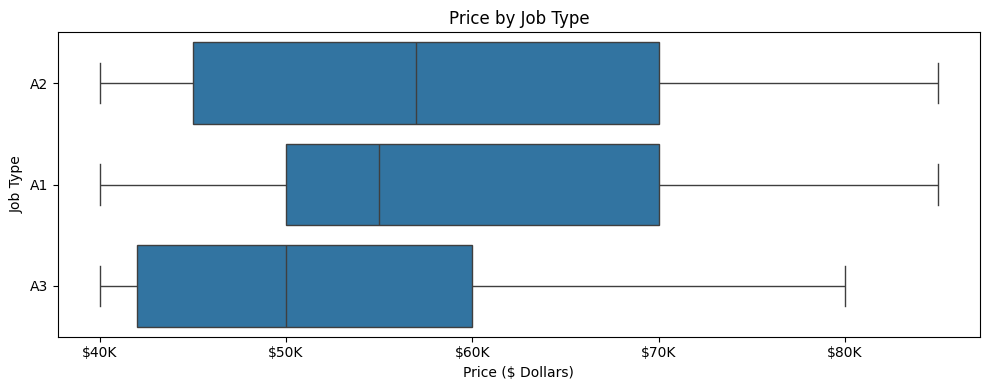

In [19]:
# finding average median cost for each Job Type
df_clean["Initial Cost"] = pd.to_numeric(
    df_clean["Initial Cost"].astype(str).str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)

fig, ax = plt.subplots(figsize=(10, 4))

sns.boxplot(data=df_clean, x="Initial Cost", y="Job Type", ax=ax)

ax.set_title("Price by Job Type")
ax.set_xlabel("Price ($ Dollars)")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"${x/1000:.0f}K"))

plt.tight_layout()
save_fig("boxplot_cost_by_job_type_cleaning")
plt.show()

##### Construction Cost by Job Type

**Type:** Bivariate Analysis — Job Type × Initial Cost

A1 and A2 projects show similar median construction costs, approximately $55,000–$57,000, while A3 projects have lower median costs, around $50,000. Although job classification appears to influence the distribution of costs, the considerable overlap suggests a relatively weak association within the analyzed price range.

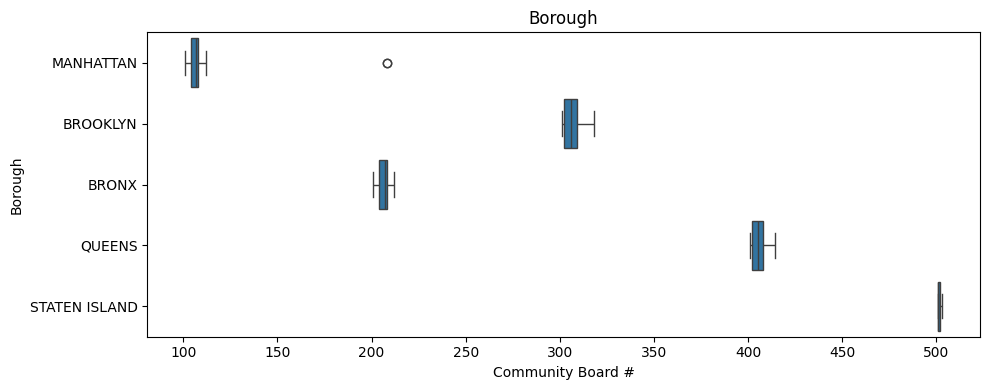

In [20]:
# Comparing Boroughs to Board # to identify mistakes
df_clean["Community - Board"] = pd.to_numeric(
    df_clean["Community - Board"].astype(str).str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)

fig, ax = plt.subplots(figsize=(10, 4))

sns.boxplot(data=df_clean, x="Community - Board", y="Borough", ax=ax)

ax.set_title("Borough")
ax.set_xlabel("Community Board #")

plt.tight_layout()
save_fig("boxplot_community_board_by_borough")
plt.show()

##### Community Board Distribution by Borough

**Type:** Bivariate Analysis — Community Board × Borough

The boxplot reveals a clear relationship between boroughs and their community board identification numbers. Each borough occupies a distinct numerical range, allowing inconsistencies to be identified. An unusual value appears in Manhattan's records, potentially indicating a classification or data-entry error that requires verification.

In [21]:
# removing data with crucial information
rows_before = len(df_clean)
df_clean = df_clean.dropna(subset=["Initial Cost"]).reset_index(drop=True)
print(f"Removed {rows_before - len(df_clean):,} listings without Initial Cost")

rows_before = len(df_clean)
df_clean = df_clean.dropna(subset=["Borough"]).reset_index(drop=True)
print(f"Removed {rows_before - len(df_clean):,} listings without Borough")

Removed 0 listings without Initial Cost
Removed 0 listings without Borough


In [22]:
# save the cleaned dataset so the analysis can start from it
df_clean.to_csv(DATA_DIR / "apartment_data_clean.csv", index=False)
print(f"Saved {len(df_clean):,} rows to {DATA_DIR / 'apartment_data_clean.csv'}")

Saved 13,470 rows to ../data/apartment_data_clean.csv


In [23]:
#
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13470 entries, 0 to 13469
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Job #                  13470 non-null  int64  
 1   Borough                13470 non-null  object 
 2   House #                13470 non-null  object 
 3   Street Name            13470 non-null  object 
 4   Block                  13470 non-null  int64  
 5   Lot                    13470 non-null  int64  
 6   Bin #                  13470 non-null  int64  
 7   Job Type               13470 non-null  object 
 8   Community - Board      13470 non-null  int64  
 9   Fully Permitted        10728 non-null  object 
 10  Initial Cost           13470 non-null  float64
 11  Zoning Dist1           12009 non-null  object 
 12  Job Description        13470 non-null  object 
 13  Initial Cost Original  13470 non-null  Float64
dtypes: Float64(1), float64(1), int64(5), object(7)
memory 

## 3 Data Analysis 

In [24]:
# Prepare a copy of the cleaned data for the EDA charts
eda_df = df_clean.copy()

# Full date and year from "Fully Permitted"
eda_df["Date"] = pd.to_datetime(eda_df["Fully Permitted"], format="%m/%d/%Y", errors="coerce")
eda_df["Year"] = eda_df["Date"].dt.year

# Zoning type = first letter of the zoning district (R = residential, C = commercial, M = manufacturing)
eda_df["Zoning Type"] = eda_df["Zoning Dist1"].str[0]

# Reusable "$65K" label format
k_format = FuncFormatter(lambda v, pos: f"${v/1000:.0f}K")

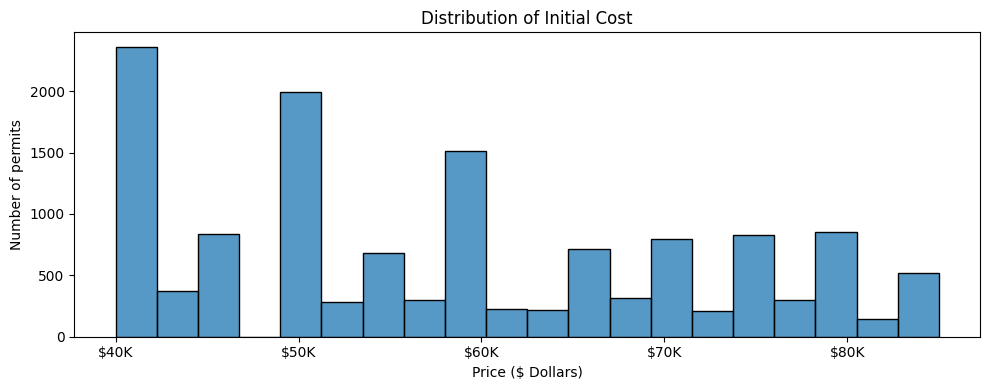

In [25]:
fig, ax = plt.subplots(figsize=(10, 4))

sns.histplot(eda_df["Initial Cost"], bins=20, ax=ax)

ax.set_title("Distribution of Initial Cost")
ax.set_xlabel("Price ($ Dollars)")
ax.set_ylabel("Number of permits")
ax.xaxis.set_major_formatter(k_format)

plt.tight_layout()
save_fig("histogram_cost_distribution")
plt.show()

##### Distribution of Initial Construction Costs

**Type:** Univariate Analysis — Initial Cost

The histogram shows the frequency of construction projects across different cost ranges. Projects are concentrated at specific values, particularly around $40,000, $50,000, and $60,000, suggesting that initial costs are frequently reported in rounded amounts. The distribution is uneven, with fewer observations at some intermediate values and higher cost levels.

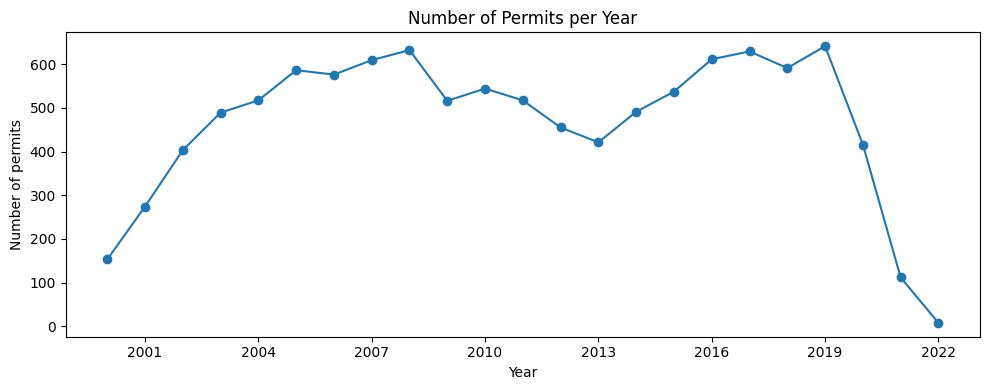

In [26]:
permits_per_year = eda_df["Year"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(permits_per_year.index, permits_per_year.values, marker="o")

ax.set_title("Number of Permits per Year")
ax.set_xlabel("Year")
ax.set_ylabel("Number of permits")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))

plt.tight_layout()
save_fig("linechart_permits_per_year")
plt.show()

##### Number of Permits per Year

**Type:** Univariate Time-Series Analysis — Permit Counts Over Time

The number of recorded permits generally increased between 2000 and 2010, followed by fluctuations and a peak around 2017. A significant decline appears after 2019, particularly in 2021 and 2022. However, this decline should be interpreted cautiously, as it may reflect incomplete data coverage rather than an actual reduction in construction activity.

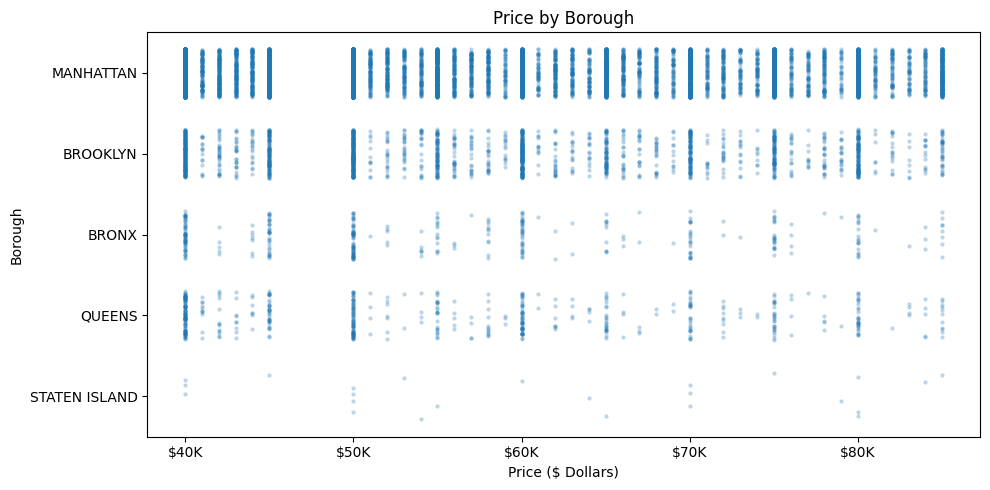

In [27]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.stripplot(data=eda_df, x="Initial Cost", y="Borough", jitter=0.3, alpha=0.3, size=3, ax=ax)

ax.set_title("Price by Borough")
ax.set_xlabel("Price ($ Dollars)")
ax.xaxis.set_major_formatter(k_format)

plt.tight_layout()
save_fig("stripplot_cost_by_borough")
plt.show()

##### Construction Cost by Borough — Strip Plot

**Type:** Bivariate Analysis — Borough × Initial Cost

Manhattan accounts for the highest concentration of construction projects, followed by Brooklyn. All five boroughs show projects across a similar cost range. The main difference is the number of observations rather than a clear geographical pattern in costs, suggesting that location alone does not explain cost variation.

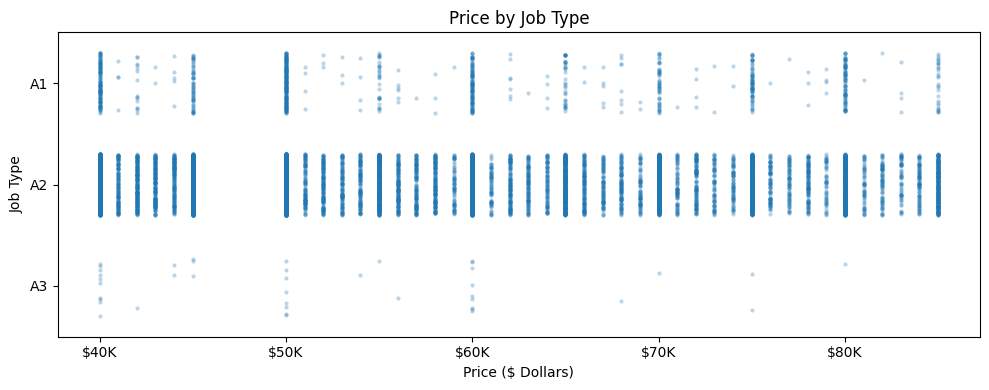

In [28]:
fig, ax = plt.subplots(figsize=(10, 4))

sns.stripplot(data=eda_df, x="Initial Cost", y="Job Type", order=["A1", "A2", "A3"],
              jitter=0.3, alpha=0.3, size=3, ax=ax)

ax.set_title("Price by Job Type")
ax.set_xlabel("Price ($ Dollars)")
ax.xaxis.set_major_formatter(k_format)

plt.tight_layout()
save_fig("stripplot_cost_by_job_type")
plt.show()

##### Construction Cost by Job Type — Strip Plot

**Type:** Bivariate Analysis — Job Type × Initial Cost

A2 projects represent the vast majority of observations, covering the full cost range. A1 projects are less frequent but show a similar distribution, while A3 projects are relatively rare. This suggests that job type is strongly associated with project frequency, but differences in construction costs are less evident.

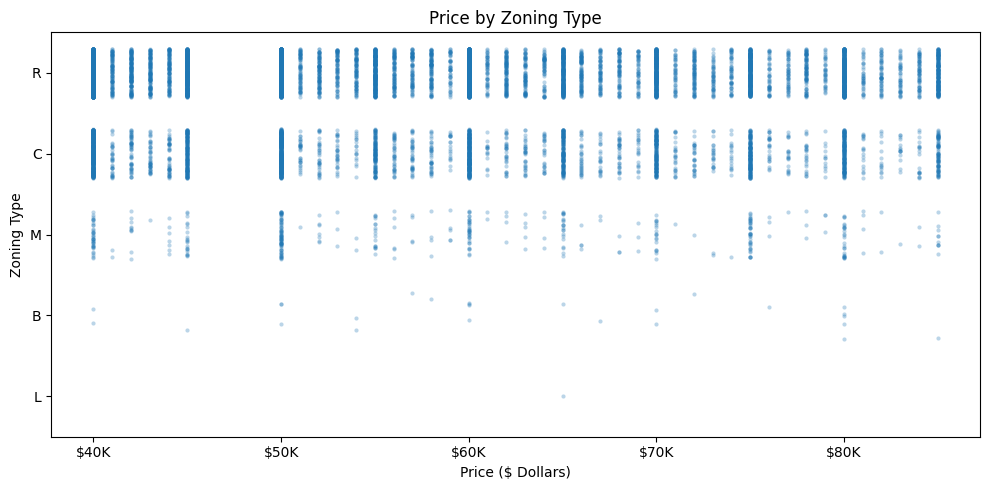

In [29]:
zoning_order = eda_df["Zoning Type"].value_counts().index

fig, ax = plt.subplots(figsize=(10, 5))

sns.stripplot(data=eda_df, x="Initial Cost", y="Zoning Type", order=zoning_order,
              jitter=0.3, alpha=0.3, size=3, ax=ax)

ax.set_title("Price by Zoning Type")
ax.set_xlabel("Price ($ Dollars)")
ax.xaxis.set_major_formatter(k_format)

plt.tight_layout()
save_fig("stripplot_cost_by_zoning_type")
plt.show()

##### Construction Cost by Zoning Type — Strip Plot

**Type:** Bivariate Analysis — Zoning Type × Initial Cost

Residential (R) and commercial (C) zones contain the majority of projects, with costs distributed across the entire analyzed range ($40,000–$85,000). Manufacturing (M) zones have fewer observations, while B and L are barely represented. The substantial overlap suggests no clear association between zoning classification and construction costs.

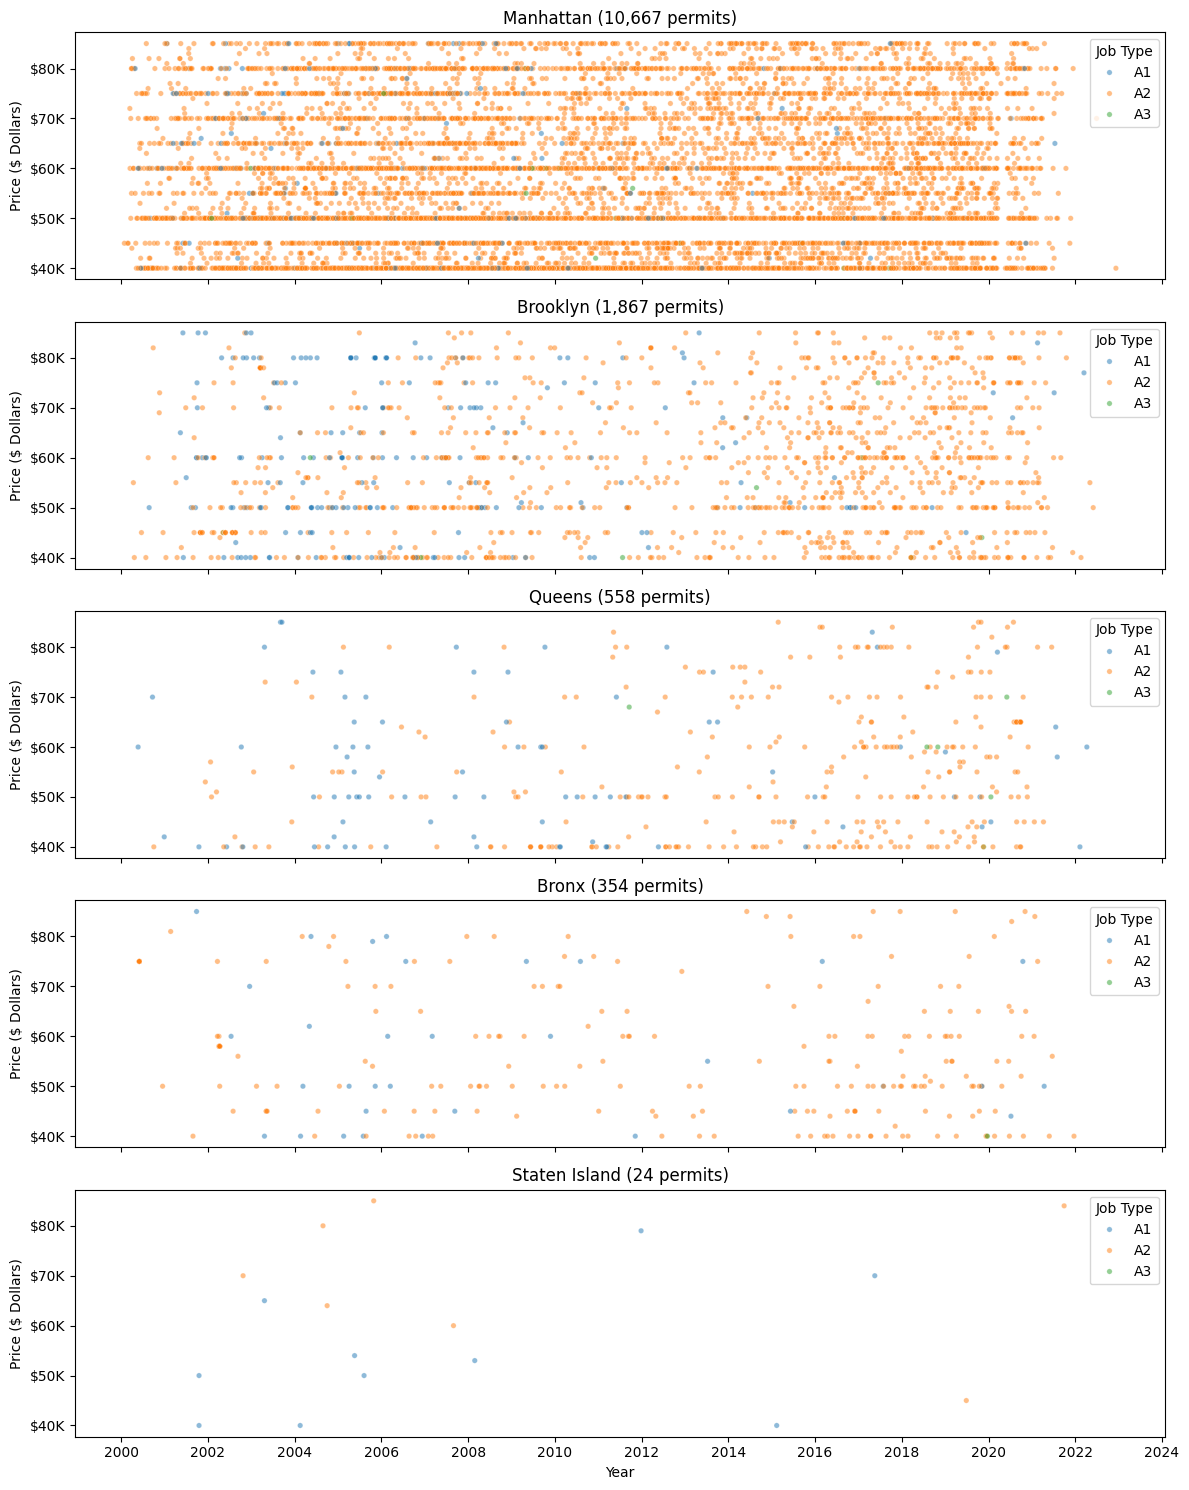

In [30]:
boroughs = eda_df["Borough"].value_counts().index

fig, axes = plt.subplots(len(boroughs), 1, figsize=(12, 3 * len(boroughs)), sharex=True, sharey=True)

for ax, borough in zip(axes, boroughs):
    data = eda_df[eda_df["Borough"] == borough]

    sns.scatterplot(data=data, x="Date", y="Initial Cost", hue="Job Type",
                    hue_order=["A1", "A2", "A3"], alpha=0.5, s=15, ax=ax)

    ax.set_title(f"{borough.title()} ({len(data):,} permits)")
    ax.set_xlabel("Year")
    ax.set_ylabel("Price ($ Dollars)")
    ax.yaxis.set_major_formatter(k_format)
    ax.legend(title="Job Type", loc="upper right")

axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.tight_layout()
save_fig("scatter_cost_over_time_by_borough")
plt.show()

##### Construction Costs Over Time by Borough and Job Type

**Type:** Multivariate Analysis — Year × Initial Cost × Borough × Job Type

The scatter plots show the distribution of construction costs over time across the five boroughs, differentiated by job type. A2 projects dominate the dataset, particularly in Manhattan and Brooklyn. Costs are widely distributed across the analyzed period, without a clear overall trend. The significant differences in sample sizes between boroughs make direct comparisons more difficult

In [31]:
def cost_boxplot(column, title):
    # Only rows that have a value in this column
    data = eda_df.dropna(subset=[column])

    # Order categories from highest to lowest median cost
    order = data.groupby(column)["Initial Cost"].median().sort_values(ascending=False).index
    counts = data[column].value_counts()

    fig, ax = plt.subplots(figsize=(10, 0.8 * len(order) + 1.5))

    sns.boxplot(data=data, x="Initial Cost", y=column, order=order,
                showmeans=True,
                meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black"},
                ax=ax)

    # Add the number of permits to each label
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels([f"{c}  (n={counts[c]:,})" for c in order])

    ax.set_title(title)
    ax.set_xlabel("Price ($ Dollars)")
    ax.set_ylabel(column)
    ax.xaxis.set_major_formatter(k_format)

    plt.tight_layout()
    save_fig("boxplot_cost_by_" + column.lower().replace(" ", "_"))
    plt.show()

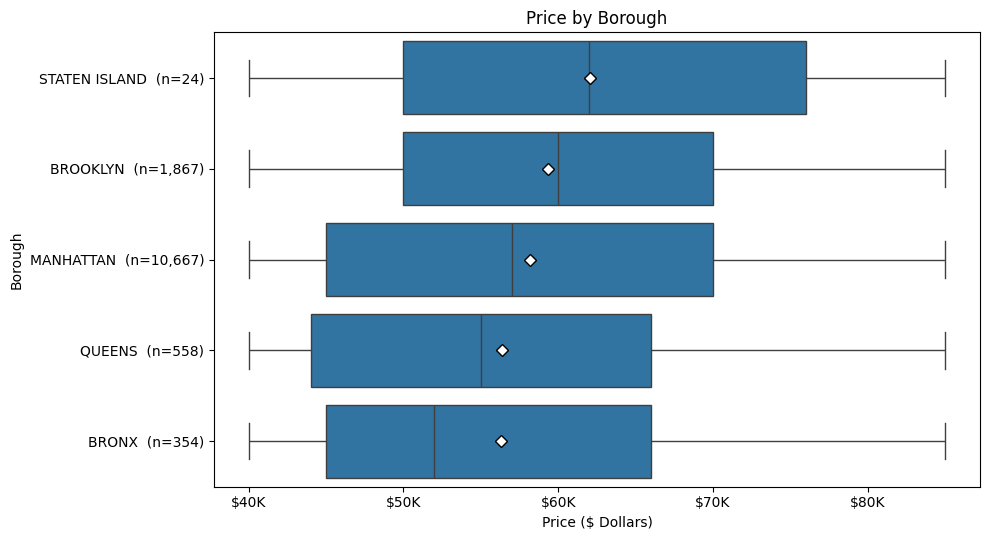

In [32]:
cost_boxplot("Borough", "Price by Borough")

##### Construction Cost by Borough

**Type:** Bivariate Analysis — Borough × Initial Cost

Staten Island and Brooklyn show the highest median construction costs, approximately $62,000 and $60,000, while the Bronx has the lowest, around $52,000. Despite these differences, the cost distributions overlap significantly, suggesting that borough location alone is not a strong predictor of construction cost within this dataset.

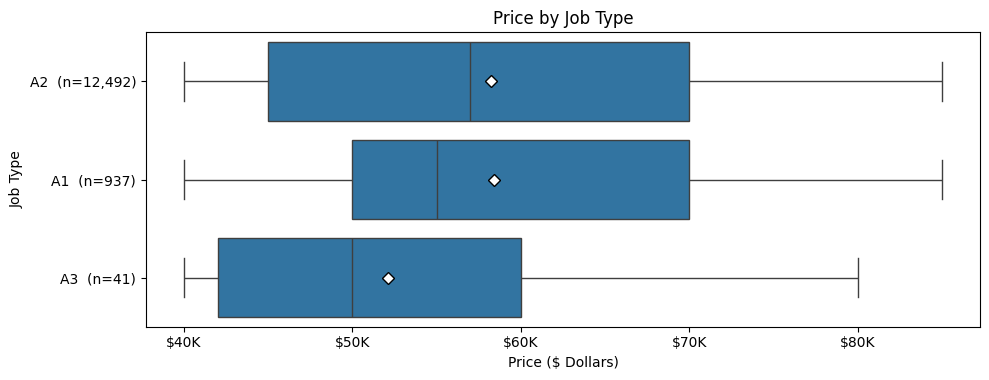

In [33]:
cost_boxplot("Job Type", "Price by Job Type")

##### Construction Cost by Job Type

Type: Bivariate Analysis — Job Type × Initial Cost

Job types A1 and A2 show relatively similar construction costs, with median values around $55,000–$57,000. A3 projects have a lower median cost of approximately $50,000. This suggests an association between job classification and construction costs, although the distributions overlap considerably and A3 has a much smaller sample.

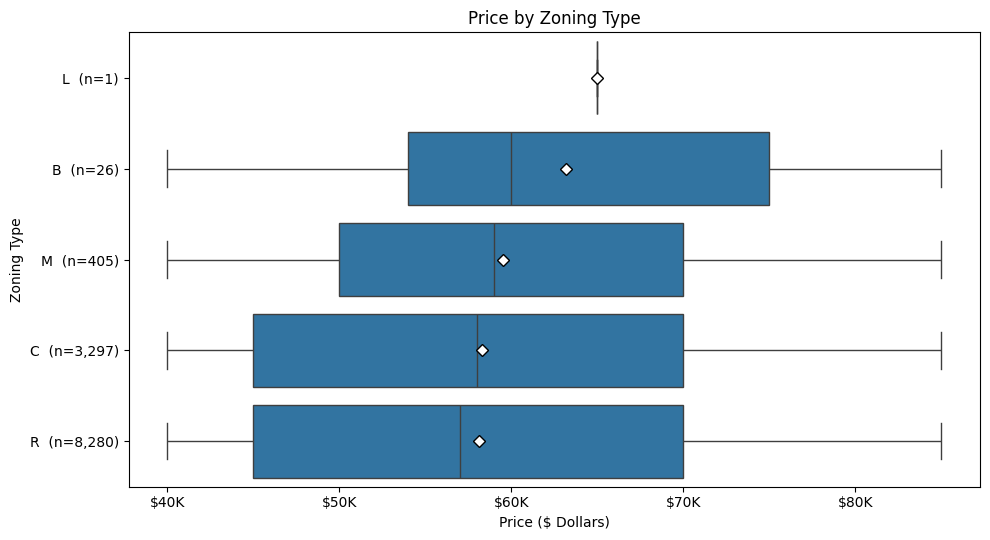

In [34]:
cost_boxplot("Zoning Type", "Price by Zoning Type")

##### Construction Cost by Zoning Type

**Type:** Bivariate Analysis — Zoning Type × Initial Cost

Median construction costs are relatively similar across residential (R), commercial (C), and manufacturing (M) zones, ranging approximately from $57,000 to $58,000. This suggests a weak association between zoning classification and construction costs within the analyzed range. Categories B and L have very limited observations, making their results less reliable.

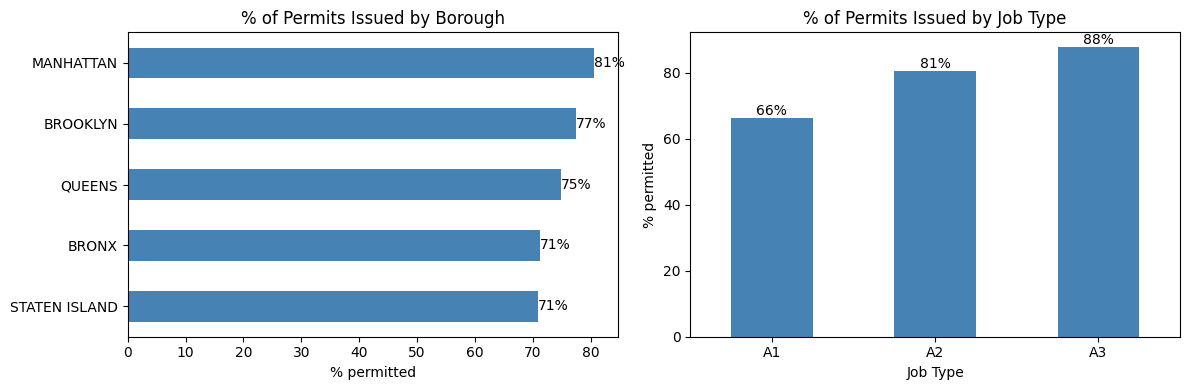

In [35]:
# True if the permit has a "Fully Permitted" date, False if it's empty
eda_df["Is Permitted"] = eda_df["Fully Permitted"].notna()
eda_df["Status"] = eda_df["Is Permitted"].map({True: "Permitted", False: "Not permitted"})

# % of permits issued, per borough and per job type
rate_borough = eda_df.groupby("Borough")["Is Permitted"].mean().mul(100).sort_values()
rate_job = eda_df.groupby("Job Type")["Is Permitted"].mean().mul(100)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

rate_borough.plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("% of Permits Issued by Borough")
axes[0].set_xlabel("% permitted")
axes[0].set_ylabel("")
axes[0].bar_label(axes[0].containers[0], fmt="%.0f%%")

rate_job.plot(kind="bar", ax=axes[1], color="steelblue", rot=0)
axes[1].set_title("% of Permits Issued by Job Type")
axes[1].set_ylabel("% permitted")
axes[1].set_xlabel("Job Type")
axes[1].bar_label(axes[1].containers[0], fmt="%.0f%%")

plt.tight_layout()
save_fig("barchart_permit_rate")
plt.show()

##### Percentage of Permits Issued by Borough and Job Type

**Type:** Two Bivariate Analyses — Borough × Permit Status and Job Type × Permit Status

The first chart shows that Manhattan has the highest recorded permitting rate (81%), while Staten Island has the lowest (71%).

The second chart reveals a stronger difference between job types: A3 has the highest recorded permitting rate (88%), followed by A2 (81%) and A1 (67%). This suggests that both location and job classification are associated with permitting rates, with larger differences observed between job types

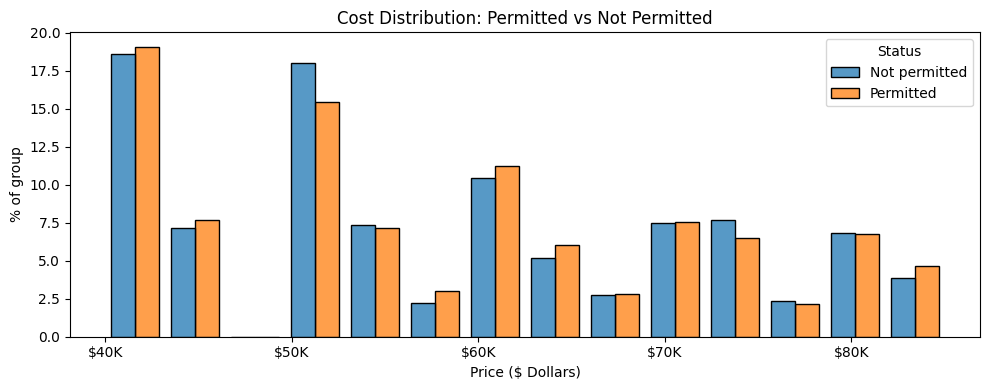

In [36]:
# Do permitted and not permitted jobs have different costs?
fig, ax = plt.subplots(figsize=(10, 4))

sns.histplot(data=eda_df, x="Initial Cost", hue="Status", stat="percent",
             common_norm=False, multiple="dodge", bins=14, shrink=0.8, ax=ax)

ax.set_title("Cost Distribution: Permitted vs Not Permitted")
ax.set_xlabel("Price ($ Dollars)")
ax.set_ylabel("% of group")
ax.xaxis.set_major_formatter(k_format)

plt.tight_layout()
save_fig("histogram_cost_permitted_vs_not")
plt.show()

##### Construction Costs: Permitted vs. Not Permitted

**Type:** Bivariate Analysis — Initial Cost × Permit Status

The cost distributions of both groups are very similar, with higher concentrations around $40,000–$60,000. This suggests that initial construction cost does not show a strong association with recorded permit status within the analyzed price range.

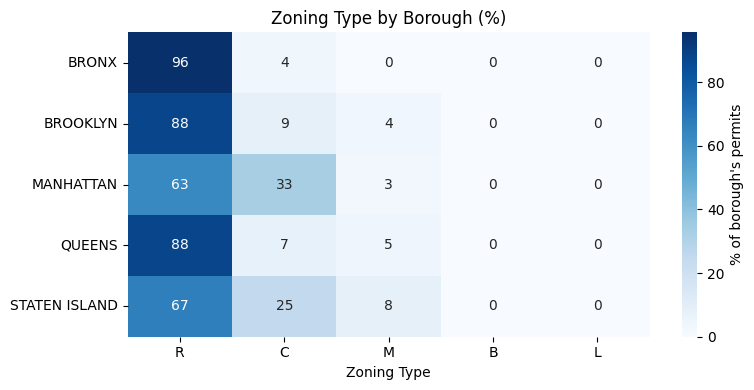

In [37]:
# % of each borough's permits in each zoning type
zoning_table = pd.crosstab(eda_df["Borough"], eda_df["Zoning Type"], normalize="index") * 100
zoning_table = zoning_table[eda_df["Zoning Type"].value_counts().index]   # most common zoning first

fig, ax = plt.subplots(figsize=(8, 4))

sns.heatmap(zoning_table, annot=True, fmt=".0f", cmap="Blues",
            cbar_kws={"label": "% of borough's permits"}, ax=ax)

ax.set_title("Zoning Type by Borough (%)")
ax.set_xlabel("Zoning Type")
ax.set_ylabel("")

plt.tight_layout()
save_fig("heatmap_zoning_type_by_borough")
plt.show()

##### Zoning Type by Borough

**Type:** Bivariate Analysis — Borough × Zoning Type

Residential zoning (R) dominates across all five boroughs. However, Manhattan has a substantially higher proportion of commercial zoning (33%) compared with Brooklyn (9%) and the Bronx (4%). This demonstrates a clear association between geographical location and zoning classification.

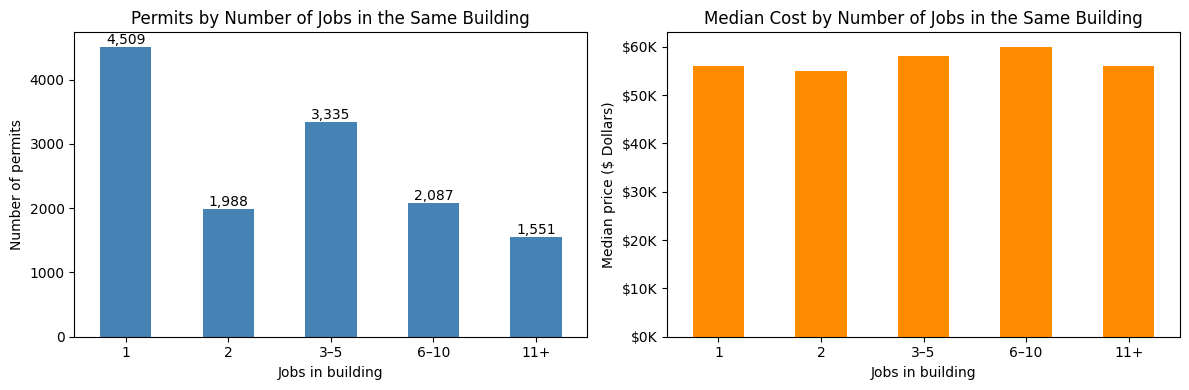

In [38]:
# Remove placeholder building IDs (NYC uses 1000000, 2000000... when the ID is unknown)
buildings = eda_df[eda_df["Bin #"] % 1_000_000 != 0].copy()

# How many jobs each building has in the data
buildings["Jobs in Building"] = buildings.groupby("Bin #")["Job #"].transform("count")
buildings["Job Group"] = pd.cut(buildings["Jobs in Building"],
                                bins=[0, 1, 2, 5, 10, 10_000],
                                labels=["1", "2", "3–5", "6–10", "11+"])

summary = buildings.groupby("Job Group", observed=True).agg(
    Permits=("Job #", "count"),
    Median_Cost=("Initial Cost", "median"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

summary["Permits"].plot(kind="bar", ax=axes[0], color="steelblue", rot=0)
axes[0].set_title("Permits by Number of Jobs in the Same Building")
axes[0].set_xlabel("Jobs in building")
axes[0].set_ylabel("Number of permits")
axes[0].bar_label(axes[0].containers[0], fmt="{:,.0f}")

summary["Median_Cost"].plot(kind="bar", ax=axes[1], color="darkorange", rot=0)
axes[1].set_title("Median Cost by Number of Jobs in the Same Building")
axes[1].set_xlabel("Jobs in building")
axes[1].set_ylabel("Median price ($ Dollars)")
axes[1].yaxis.set_major_formatter(k_format)

plt.tight_layout()
save_fig("barchart_jobs_per_building")
plt.show()

##### Number of Jobs per Building vs. Construction Costs

**Type:** Univariate (left) + Bivariate (right)

The first chart shows how permits are distributed according to the number of jobs recorded in each building, with buildings containing 3–5 jobs representing the largest group.

The second chart compares the median construction cost across these groups. Costs remain relatively stable, around $56,000–$60,000, suggesting no strong association between the number of jobs in a building and the cost of an individual project.

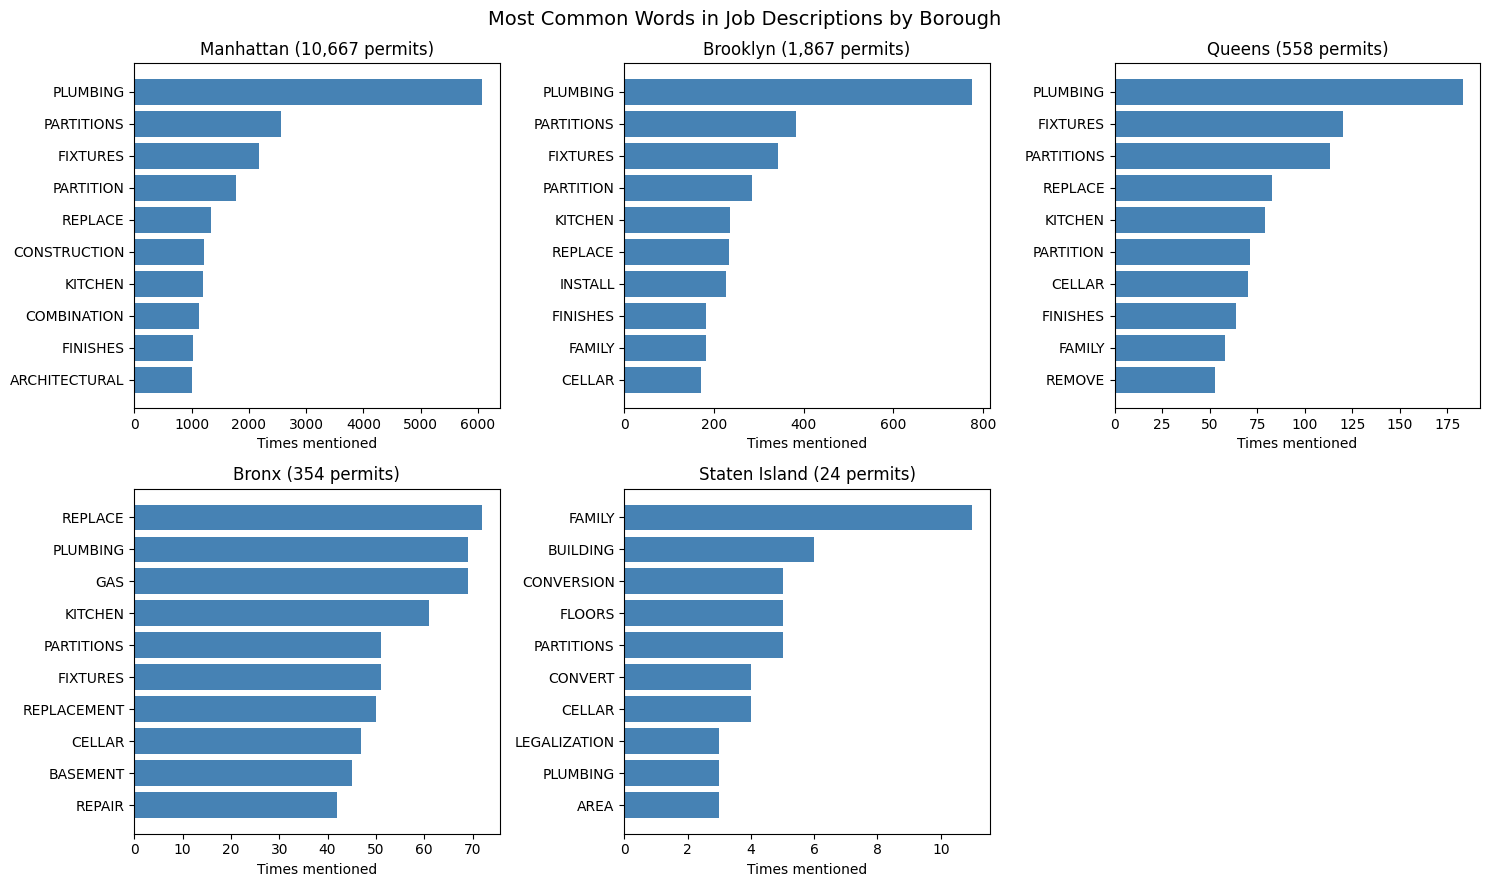

In [39]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Words to ignore: common English words + words that appear in almost every description
extra_stopwords = {
    "APARTMENT", "APARTMENTS", "APT", "RENOVATION", "RENOVATE", "EXISTING",
    "PROPOSED", "PROPOSE", "CHANGE", "USE", "EGRESS", "OCCUPANCY", "FILING",
    "HEREBY", "APPLICATION", "WORK", "FLOOR", "NEW", "INTERIOR", "AMP",
    "PER", "PLANS", "FILED", "TYPE", "SCOPE", "INCLUDE", "INCLUDES", "INCLUDING", 
    "HEREWITH", "SECOND", "NON", "STORY", "LEGALIZE", "MECHANICAL", "MINOR"}
stopwords = {w.upper() for w in ENGLISH_STOP_WORDS} | extra_stopwords

def top_words(texts, n=10):
    words = texts.str.upper().str.findall(r"[A-Z]{3,}").explode()
    words = words[~words.isin(stopwords)]
    return words.value_counts().head(n)

boroughs = df_clean["Borough"].value_counts().index

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for ax, borough in zip(axes, boroughs):
    descriptions = df_clean.loc[df_clean["Borough"] == borough, "Job Description"].dropna()
    words = top_words(descriptions).sort_values()

    ax.barh(words.index, words.values, color="steelblue")
    ax.set_title(f"{borough.title()} ({len(descriptions):,} permits)")
    ax.set_xlabel("Times mentioned")

axes[-1].axis("off")   # 5 boroughs, 6 spaces: hide the empty one

plt.suptitle("Most Common Words in Job Descriptions by Borough", fontsize=14)
plt.tight_layout()
save_fig("barchart_common_words_by_borough")
plt.show()

##### Most common wordsin job description by borough

**Type:** Multivariate

Plumbing is the most frequently mentioned activity in Manhattan, Brooklyn, and Queens, while the Bronx shows more references to gas and replacement works. Staten Island has a different pattern, although its sample is significantly smaller. These results suggest differences in renovation activities across boroughs, but comparisons should account for the unequal number of permits.

### 3.1 Correlation Analysis

Pearson correlation between the numeric columns of the cleaned dataset. `Is Permitted` is a 0/1 flag, so its coefficient reads as a point-biserial correlation.

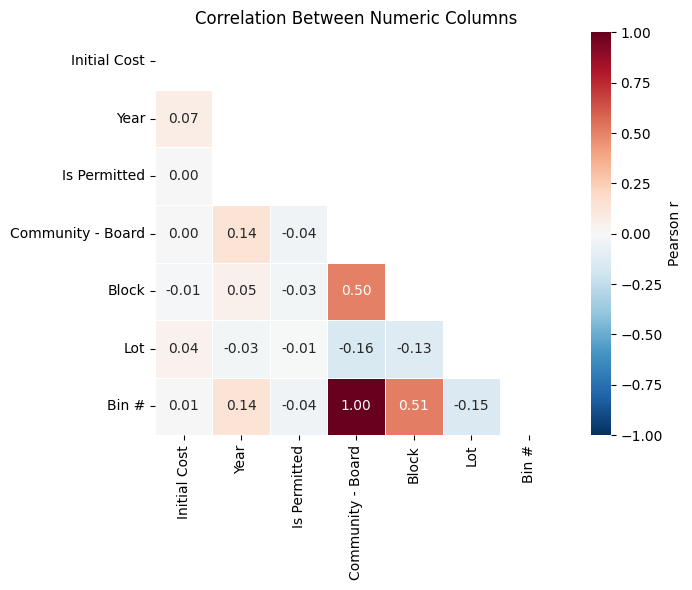

Year                 0.074
Lot                  0.040
Block               -0.010
Bin #                0.005
Community - Board    0.004
Is Permitted         0.003
Name: Initial Cost, dtype: float64

In [40]:
# numeric columns that carry a quantity or an order (Job # is a pure ID, so it is left out)
corr_cols = ["Initial Cost", "Year", "Is Permitted", "Community - Board", "Block", "Lot", "Bin #"]
corr = eda_df[corr_cols].astype(float).corr()

# show only the lower triangle: the matrix is symmetric
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"label": "Pearson r"}, ax=ax)

ax.set_title("Correlation Between Numeric Columns")

plt.tight_layout()
save_fig("heatmap_correlation")
plt.show()

# correlations with Initial Cost, strongest first
corr["Initial Cost"].drop("Initial Cost").sort_values(key=abs, ascending=False).round(3)

##### Correlation Between Numeric Columns

**Type:** Multivariate Analysis — all numeric columns

**Initial Cost is practically uncorrelated with every other numeric column.** The strongest link is with Year (r ≈ 0.07), a very weak positive trend in which more recent permits are slightly more expensive. Correlations with Is Permitted, Block, Lot, Bin # and Community Board are all below 0.05 in absolute value. This agrees with the boxplots above: within the cleaned $40K–$85K range, none of these variables explains renovation cost on its own.

The only strong correlations are between location codes. Community Board and Bin # are almost perfectly correlated (r ≈ 1.00), and both correlate with Block (r ≈ 0.5). This is not a real relationship: NYC numbers community boards and building IDs by borough (1 = Manhattan, 2 = Bronx, 3 = Brooklyn, 4 = Queens, 5 = Staten Island), so all of them encode the borough. These columns are identifiers, not quantities, so their coefficients should not be read as effects. The Year × Is Permitted cell is empty because Year only exists for permitted jobs, so Is Permitted is constant wherever Year has a value.

**Correlation is not causation.** Even the weak Year–cost link does not show that time drives cost. It could reflect inflation, changes in the type of projects filed, or the incomplete coverage of recent years noted earlier. Pearson r also only measures *linear* relationships between numeric columns; categorical drivers such as job type, zoning or the work described are not captured here, and a confounding variable could hide or create an association. Establishing causes would need controlled comparisons or a model that accounts for these factors.